# Manual Linear Regression — Training from First Principles

Learn to trace tensors → parameters → predictions → loss → gradients → updates. Derive MSE gradients, verify autograd, train a linear model, and deliberately test learning-rate and gradient-reset failures before introducing PyTorch layers and optimizers. Compare SGD, Adam, AdamW, and momentum through their measured behavior.

Run this notebook from a fresh kernel in order. Every experiment uses locally defined data and parameters.

## Imports and reproducibility

Import the numerical and plotting tools and seed PyTorch before creating data or parameters. Expect repeatable random draws when running from a fresh kernel in the same environment. The device check reports accelerator availability; the tensors in this notebook remain on CPU, which also permits direct `.numpy()` plotting.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.14.1
Device: mps


## Synthetic data and observation noise

Create 100 examples with one feature each: $x$ and $y$ have shape `[100, 1]`. The known relationship is $y=3x+2+\epsilon$, with noise drawn from a normal distribution and scaled by 0.2. Noise makes observations imperfect, so expect parameters near 3 and 2 and a nonzero residual loss rather than an exact fit.

In [2]:
x = torch.linspace(-2, 2, 100).reshape(-1, 1)

noise = 0.2 * torch.randn(100, 1)

y = 3 * x + 2 + noise

print("x shape:", x.shape)
print("y shape:", y.shape)

print("\nFirst 5 x values:")
print(x[:5])

print("\nFirst 5 y values:")
print(y[:5])

x shape: torch.Size([100, 1])
y shape: torch.Size([100, 1])

First 5 x values:
tensor([[-2.0000],
        [-1.9596],
        [-1.9192],
        [-1.8788],
        [-1.8384]])

First 5 y values:
tensor([[-3.6146],
        [-3.5813],
        [-3.5774],
        [-4.0575],
        [-3.3795]])


The printed shapes confirm 100 examples with one feature and one target each. The observations include noise, so the fitted line should capture the trend rather than pass through every point.

## Inspect the data visually

Plot the observations before training to check the range and relationship. Expect an upward line with scatter around it; this checks that the dataset matches the intended regression problem.

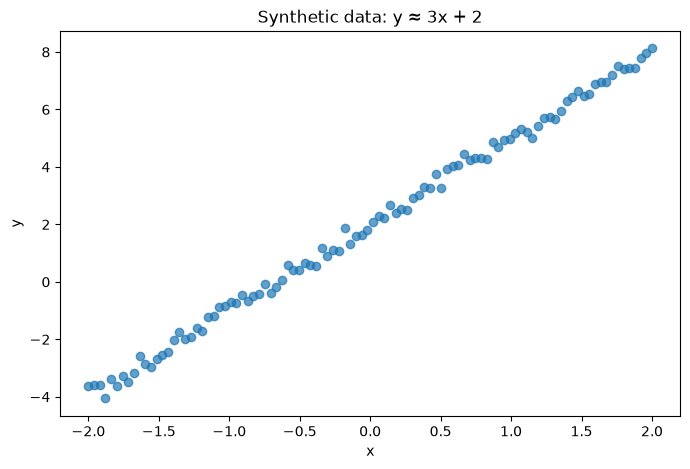

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(x.numpy(), y.numpy(), alpha=0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic data: y ≈ 3x + 2")
plt.show()

The scatter plot shows the intended approximately linear trend. This supports using a linear model as a controlled first training problem.

## Learnable parameters: weight and bias

The model is $\hat y=xw+b$. The weight $w$ is the slope and $b$ shifts the line vertically. `torch.randn(1, 1)` samples a standard normal starting weight; `torch.zeros(1)` starts the bias at zero. `requires_grad=True` makes these leaf tensors eligible for gradient computation. Expect arbitrary initial predictions, not the known data-generating parameters.

In [4]:
w = torch.randn(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

print("Initial w:", w.item())
print("Initial b:", b.item())

Initial w: -0.5671805739402771
Initial b: 0.0


The initialized weight and zero bias define the starting line. They are learnable tensors, distinct from the fixed input and target data.

## Forward pass and tensor shapes

Compute predictions without changing parameters. Matrix multiplication `[100, 1] @ [1, 1]` yields `[100, 1]`; the bias `[1]` broadcasts across examples. Expect the prediction shape to match the target shape and the initial values to differ from the noisy targets.

In [5]:
y_pred = x @ w + b

print("Prediction shape:", y_pred.shape)
print("First 5 predictions:")
print(y_pred[:5])

print("\nFirst 5 targets:")
print(y[:5])

Prediction shape: torch.Size([100, 1])
First 5 predictions:
tensor([[1.1344],
        [1.1114],
        [1.0885],
        [1.0656],
        [1.0427]], grad_fn=<SliceBackward0>)

First 5 targets:
tensor([[-3.6146],
        [-3.5813],
        [-3.5774],
        [-4.0575],
        [-3.3795]])


## Mean squared error

Turn prediction errors into one scalar training objective:

$$
L=\frac{1}{N}\sum_{i=1}^{N}(\hat y_i-y_i)^2.
$$

Squaring penalizes large errors and prevents positive and negative errors from cancelling. Expect a nonnegative scalar; lower MSE means a closer fit to these targets.

In [6]:
errors = y_pred - y
squared_errors = errors ** 2
loss = squared_errors.mean()

print("Loss:", loss.item())

Loss: 21.367002487182617


## The computational graph

Operations involving $w$ and $b$ connect predictions and loss to the parameters through an autograd graph. Inspect gradient tracking before backpropagation. Expect predictions and loss to require gradients, while parameter `.grad` fields are still `None`: building the graph does not compute gradients yet.

In [7]:
print("y_pred requires_grad:", y_pred.requires_grad)
print("loss requires_grad:", loss.requires_grad)
print("w grad before backward:", w.grad)
print("b grad before backward:", b.grad)

y_pred requires_grad: True
loss requires_grad: True
w grad before backward: None
b grad before backward: None


## Backpropagation and the meaning of gradients

`loss.backward()` applies the chain rule through the graph and accumulates derivatives in `w.grad` and `b.grad`. A gradient measures how loss changes locally as a parameter increases. A negative gradient suggests increasing that parameter to reduce loss; a positive gradient suggests decreasing it. Expect one derivative per parameter; backward does not update parameter values.

In [8]:
loss.backward()

print("w gradient:", w.grad)
print("b gradient:", b.grad)

w gradient: tensor([[-9.6966]])
b gradient: tensor([-4.0239])


The printed gradients are populated after backward. Their signs determine the direction of the next descent step; their magnitudes interact with the learning rate to determine its size.

## First manual parameter update

Apply one gradient-descent step with learning rate 0.05:

$$
\theta_{\mathrm{new}}=\theta_{\mathrm{old}}-\eta\frac{\partial L}{\partial\theta}.
$$

Use `torch.no_grad()` so the update itself is not recorded as part of the prediction graph. Expect movement opposite the gradient; recomputing the loss next will test whether this step helped.

In [9]:
learning_rate = 0.05

print("Before update")
print("w:", w.item())
print("b:", b.item())
print("loss:", loss.item())

with torch.no_grad():
    w -= learning_rate * w.grad
    b -= learning_rate * b.grad

print("\nAfter update")
print("w:", w.item())
print("b:", b.item())

Before update
w: -0.5671805739402771
b: 0.0
loss: 21.367002487182617

After update
w: -0.08234885334968567
b: 0.20119528472423553


## Measure the effect of the update

Recompute predictions and loss using the updated parameters. The old loss tensor holds the previous forward-pass value; it does not automatically refresh when parameters change. Expect the new loss to be lower for this learning rate.

In [10]:
y_pred_new = x @ w + b
loss_new = ((y_pred_new - y) ** 2).mean()

print("Old loss:", loss.item())
print("New loss:", loss_new.item())

Old loss: 21.367002487182617
New loss: 16.21640396118164


The new loss is lower than the old loss in the saved result. One step improved the fit, but repeated forward passes and updates are needed for convergence.

## Deriving the gradient manually

For $\hat y_i=x_iw+b$ and mean squared error, the chain rule gives:

$$
\frac{\partial L}{\partial w}=\frac{2}{N}\sum_i(\hat y_i-y_i)x_i,\qquad
\frac{\partial L}{\partial b}=\frac{2}{N}\sum_i(\hat y_i-y_i).
$$

Compute both expressions and compare them with `loss.backward()`. Expect matching values up to floating-point rounding. Use the stored predictions from the original forward pass so the comparison refers to the same state.

In [12]:

# Compute the gradients ourselves from the MSE equations
manual_dw = (2 / len(x)) * torch.sum((y_pred - y) * x)
manual_db = (2 / len(x)) * torch.sum(y_pred - y)

print("Manual dw:", manual_dw.item())
print("PyTorch dw:", w.grad.item())

print()

print("Manual db:", manual_db.item())
print("PyTorch db:", b.grad.item())

Manual dw: -9.696633338928223
PyTorch dw: -9.696634292602539

Manual db: -4.023906230926514
PyTorch db: -4.0239057540893555


The manual derivatives match the printed autograd derivatives to floating-point precision. Both use the original `y_pred` from before the first update; this deliberately compares gradients at the same parameter state, even though `w` and `b` have since changed.

## Full gradient-descent training loop

So far, we performed only one optimization step.

Training a model means repeating the same process many times:

```text
forward pass
→ compute loss
→ compute gradients
→ update parameters
→ clear gradients
→ repeat
```


Reset the parameters and train for 100 epochs with learning rate 0.05. Expect a falling loss that settles near the noise floor. Clear gradients after each update so the next backward pass uses only the new loss.

In [13]:


# Reinitialize parameters so we can train from scratch
torch.manual_seed(42)

w = torch.randn(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

learning_rate = 0.05
epochs = 100

loss_history = []

for epoch in range(epochs):
    # 1. Forward pass: compute predictions
    y_pred = x @ w + b

    # 2. Compute Mean Squared Error loss
    loss = ((y_pred - y) ** 2).mean()

    # Save the loss so we can visualize training later
    loss_history.append(loss.item())

    # 3. Backward pass: compute gradients
    loss.backward()

    # 4. Update parameters without tracking this update in autograd
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    # 5. Clear gradients before the next iteration
    w.grad.zero_()
    b.grad.zero_()

    # Print progress every 10 epochs
    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"w: {w.item():.4f} | "
            f"b: {b.item():.4f}"
        )

Epoch   0 | Loss: 13.7138 | w: 0.6986 | b: 0.2012
Epoch  10 | Loss: 1.0477 | w: 2.4644 | b: 1.3806
Epoch  20 | Loss: 0.1261 | w: 2.8736 | b: 1.7918
Epoch  30 | Loss: 0.0473 | w: 2.9684 | b: 1.9352
Epoch  40 | Loss: 0.0395 | w: 2.9904 | b: 1.9852
Epoch  50 | Loss: 0.0386 | w: 2.9955 | b: 2.0026
Epoch  60 | Loss: 0.0385 | w: 2.9967 | b: 2.0087
Epoch  70 | Loss: 0.0385 | w: 2.9970 | b: 2.0108
Epoch  80 | Loss: 0.0385 | w: 2.9970 | b: 2.0116
Epoch  90 | Loss: 0.0385 | w: 2.9970 | b: 2.0118


In [14]:
print("Final weight:", w.item())
print("Final bias:", b.item())
print("Final loss:", loss_history[-1])

print("\nTrue weight: 3")
print("True bias: 2")

Final weight: 2.997051239013672
Final bias: 2.011899471282959
Final loss: 0.03851611912250519

True weight: 3
True bias: 2


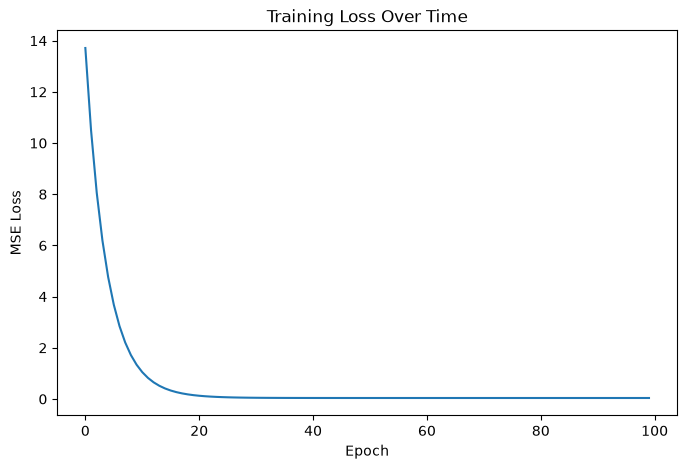

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")
plt.show()

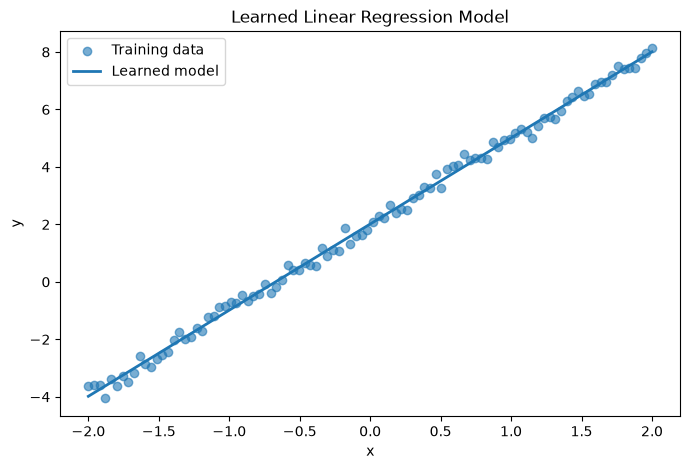

In [16]:
with torch.no_grad():
    final_predictions = x @ w + b

plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.6,
    label="Training data"
)

plt.plot(
    x.numpy(),
    final_predictions.numpy(),
    linewidth=2,
    label="Learned model"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Learned Linear Regression Model")
plt.legend()
plt.show()

## Convergence — interpretation

The saved final parameters approach $w\approx3$ and $b\approx2$, the loss curve flattens, and the fitted line follows the noisy observations. The remaining error reflects observation noise; convergence does not require zero training loss. `loss_history[-1]` was measured before the final update, while the printed parameters and plotted line are from after it.

## Learning Rate Experiment

The learning rate controls the size of each parameter update:

$$
\theta_{\text{new}}
=
\theta_{\text{old}}
-
\eta
\frac{\partial L}{\partial \theta}
$$

where:

- $\theta$ is a model parameter
- $\eta$ is the learning rate
- $\frac{\partial L}{\partial \theta}$ is the gradient

A gradient tells us the local direction and steepness of the loss.

The learning rate determines how far we move in that direction.

We will compare:

```text
very small learning rate
→ slow progress

reasonable learning rate
→ stable convergence

very large learning rate
→ overshooting or divergence
```


Hold initialization and the 50-epoch budget fixed; compare learning rates 0.001, 0.05, and 1.0. The separate log-scale plots keep the stable curves visible when the large learning rate diverges.

In [23]:

def train_linear_model(learning_rate, epochs=50):
    # Start every experiment from the same initial parameters
    # so learning rate is the only variable being changed.
    torch.manual_seed(42)

    w = torch.randn(1, 1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    losses = []

    for epoch in range(epochs):
        # Forward pass
        y_pred = x @ w + b

        # Mean Squared Error
        loss = ((y_pred - y) ** 2).mean()
        losses.append(loss.item())

        # Compute gradients
        loss.backward()

        # Gradient-descent parameter update
        with torch.no_grad():
            w -= learning_rate * w.grad
            b -= learning_rate * b.grad

        # Clear gradients before the next epoch
        w.grad.zero_()
        b.grad.zero_()

    return {
        "learning_rate": learning_rate,
        "w": w.item(),
        "b": b.item(),
        "final_loss": losses[-1],
        "losses": losses,
    }

In [24]:
small_lr = train_linear_model(0.001)
good_lr = train_linear_model(0.05)
large_lr = train_linear_model(1.0)

for result in [small_lr, good_lr, large_lr]:
    print(
        f"lr={result['learning_rate']:<6} | "
        f"w={result['w']:.4f} | "
        f"b={result['b']:.4f} | "
        f"loss={result['final_loss']:.6f}"
    )

lr=0.001  | w=0.6755 | b=0.1916 | loss=10.736904
lr=0.05   | w=2.9953 | b=2.0016 | loss=0.038655
lr=1.0    | w=-1614964981760.0000 | b=-5204.0581 | loss=1198456571776858624884736.000000


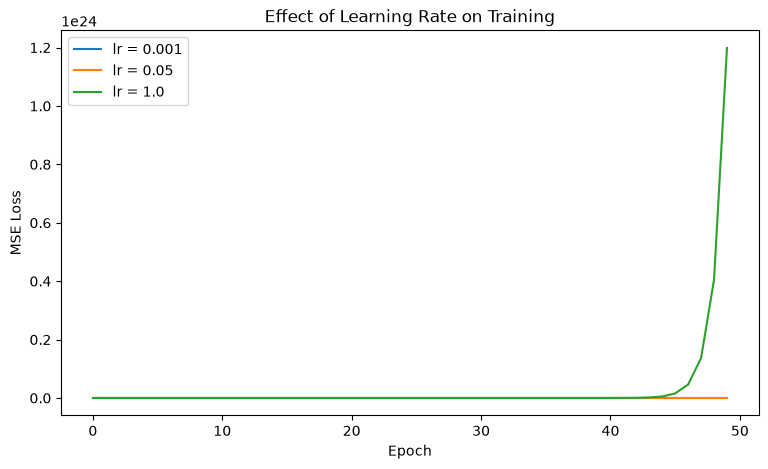

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    small_lr["losses"],
    label="lr = 0.001"
)

plt.plot(
    good_lr["losses"],
    label="lr = 0.05"
)

plt.plot(
    large_lr["losses"],
    label="lr = 1.0"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Effect of Learning Rate on Training")
plt.legend()
plt.show()

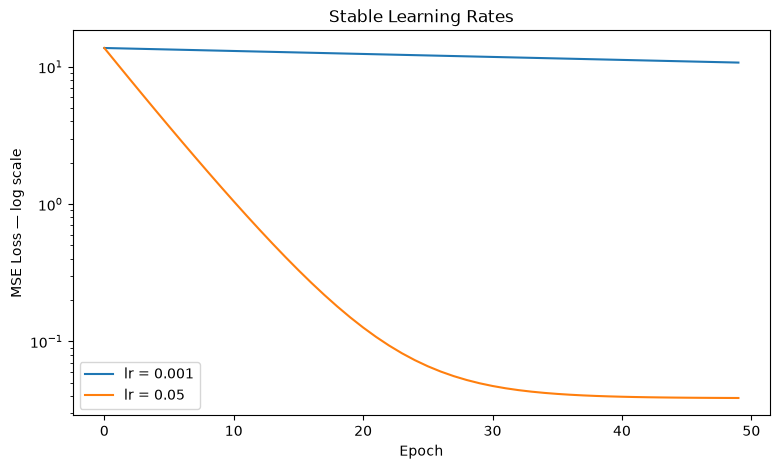

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    small_lr["losses"],
    label="lr = 0.001"
)

plt.plot(
    good_lr["losses"],
    label="lr = 0.05"
)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss — log scale")
plt.title("Stable Learning Rates")
plt.legend()
plt.show()

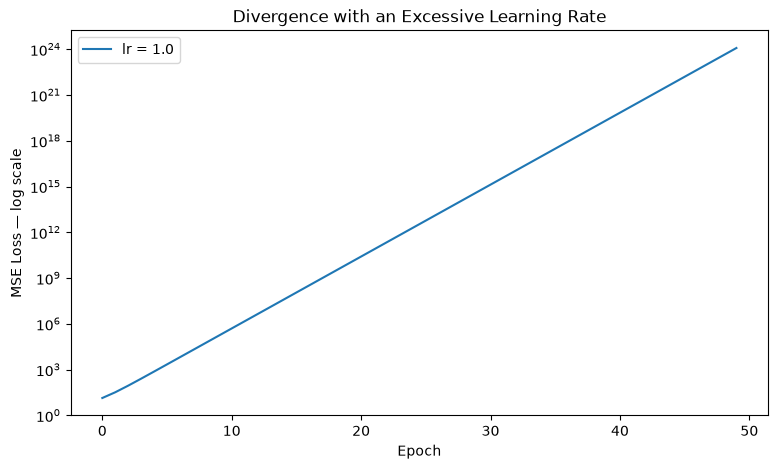

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    large_lr["losses"],
    label="lr = 1.0"
)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss — log scale")
plt.title("Divergence with an Excessive Learning Rate")
plt.legend()
plt.show()

## Learning Rate Experiment — Interpretation

The learning rate controls the size of each parameter update:

$$
\theta_{\text{new}}
=
\theta_{\text{old}}
-
\eta
\frac{\partial L}{\partial \theta}
$$

where:

- $\theta$ is a model parameter
- $\eta$ is the learning rate
- $\frac{\partial L}{\partial \theta}$ is the gradient

The gradient tells us the local direction and steepness of the loss.

The learning rate determines how far we move in that direction.

In this experiment, we compared three learning rates:

```text
0.001 → very small
0.05  → reasonable
1.0   → very large
```

The results were:

```text
lr = 0.001
w = 0.6755
b = 0.1916
loss = 10.7369

lr = 0.05
w = 2.9953
b = 2.0016
loss = 0.0387

lr = 1.0
w ≈ -1.6 × 10^12
b ≈ -5204
loss ≈ 1.2 × 10^24
```

The underlying synthetic relationship is:

$$
y \approx 3x + 2
$$

so the desired parameters are approximately:

```text
w = 3
b = 2
```

### Learning rate = 0.001

The model moved in the correct direction, but training was very slow.

After 50 epochs:

```text
w = 0.6755
b = 0.1916
loss = 10.7369
```

The parameters are moving toward the correct values, but they are still far from:

```text
w ≈ 3
b ≈ 2
```

This shows that a learning rate can be too small without being mathematically incorrect.

The updates are simply too small to reach a good solution efficiently.

Conceptually:

```text
correct direction
      ↓
very small steps
      ↓
slow convergence
```

---

### Learning rate = 0.05

This learning rate produced stable convergence.

After 50 epochs:

```text
w = 2.9953
b = 2.0016
loss = 0.0387
```

These values are very close to the true parameters:

```text
w = 3
b = 2
```

So this learning rate provided a good balance between:

```text
step size
and
training stability
```

Conceptually:

```text
useful gradient
      ↓
reasonable step size
      ↓
stable progress
      ↓
low-loss region
```

---

### Learning rate = 1.0

This learning rate caused training to diverge.

The model ended with approximately:

```text
w ≈ -1.6 × 10^12
b ≈ -5204
loss ≈ 1.2 × 10^24
```

The problem is not necessarily that the gradient points in the wrong direction.

The problem is that the learning rate makes each update far too large.

Gradient descent performs:

$$
\theta_{\text{new}}
=
\theta_{\text{old}}
-
\eta
\frac{\partial L}{\partial \theta}
$$

If $\eta$ is too large, the optimizer can jump past the low-loss region.

Instead of gradually approaching the minimum, it can repeatedly overshoot it.

Conceptually:

```text
loss surface

high loss                       high loss
        \                       /
         \                     /
          \                   /
           \      minimum    /
            \______●________/
```

A reasonable learning rate behaves roughly like:

```text
→ → → → → ●
```

A learning rate that is too large can behave more like:

```text
        ●
      ↙   ↗
   ↙         ↗
↙               ↗
```

Each overshoot can produce an even larger gradient.

That larger gradient then produces an even larger parameter update.

This feedback loop can cause the parameters and loss to explode.

This behavior is called **divergence**.

---

## Why the original plot looked almost flat

The `lr = 1.0` experiment reached a loss on the order of:

```text
10^24
```

while the other experiments had losses around:

```text
10
```

and:

```text
0.04
```

Because the values differ by many orders of magnitude, the plot's y-axis had to expand enough to display the divergent run.

As a result, the smaller losses were visually compressed near zero.

This does not mean the `0.001` and `0.05` curves behaved the same.

It only means their values were tiny relative to the exploding `1.0` run.

A logarithmic y-axis is often useful in ML when values span many orders of magnitude.

---

## Key takeaway

The gradient and learning rate play different roles:

```text
gradient
→ direction
→ local steepness

learning rate
→ size of the step
```

So:

```text
learning rate too small
→ slow convergence

learning rate reasonable
→ stable convergence

learning rate too large
→ overshooting and possible divergence
```

Successful optimization requires both:

```text
useful gradients
+
appropriate step size
```

The optimizer does not know the final correct parameter values directly.

It repeatedly uses local gradient information to move the parameters toward a region of lower loss.

## Gradient Accumulation Experiment

In the training loop, we have been clearing gradients after every parameter update:

```python
w.grad.zero_()
b.grad.zero_()
```

PyTorch does **not** automatically replace old gradients.

Instead, gradients accumulate.

Conceptually:

```text
after backward #1:
w.grad = gradient_1

after backward #2 without clearing:
w.grad = gradient_1 + gradient_2

after backward #3 without clearing:
w.grad = gradient_1 + gradient_2 + gradient_3
```

This behavior is intentional.

Gradient accumulation is useful when we explicitly want to combine gradients across multiple mini-batches.

But in ordinary gradient descent, failing to clear gradients can produce unintended parameter updates.

In this experiment, we will compare:

```text
normal training
→ clear gradients every epoch

broken training
→ never clear gradients
```

Everything else will remain the same.

In [28]:
def train_with_gradient_reset(learning_rate=0.05, epochs=20):
    # Start from the same initialization for a fair comparison
    torch.manual_seed(42)

    w = torch.randn(1, 1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    losses = []

    for epoch in range(epochs):
        # Forward pass
        y_pred = x @ w + b

        # Compute loss
        loss = ((y_pred - y) ** 2).mean()
        losses.append(loss.item())

        # Compute gradients
        loss.backward()

        # Update parameters
        with torch.no_grad():
            w -= learning_rate * w.grad
            b -= learning_rate * b.grad

        # Important: clear gradients before next epoch
        w.grad.zero_()
        b.grad.zero_()

    return {
        "w": w.item(),
        "b": b.item(),
        "losses": losses,
    }


def train_without_gradient_reset(learning_rate=0.05, epochs=20):
    # Same initialization as the correct experiment
    torch.manual_seed(42)

    w = torch.randn(1, 1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    losses = []

    for epoch in range(epochs):
        # Forward pass
        y_pred = x @ w + b

        # Compute loss
        loss = ((y_pred - y) ** 2).mean()
        losses.append(loss.item())

        # Gradients are ADDED to whatever is already in .grad
        loss.backward()

        # Update parameters using accumulated gradients
        with torch.no_grad():
            w -= learning_rate * w.grad
            b -= learning_rate * b.grad

        # Intentionally DO NOT clear gradients here

    return {
        "w": w.item(),
        "b": b.item(),
        "losses": losses,
    }

In [29]:
correct = train_with_gradient_reset()
accumulated = train_without_gradient_reset()

print("Correct training")
print("w:", correct["w"])
print("b:", correct["b"])
print("final loss:", correct["losses"][-1])

print()

print("Without gradient reset")
print("w:", accumulated["w"])
print("b:", accumulated["b"])
print("final loss:", accumulated["losses"][-1])

Correct training
w: 2.8541812896728516
b: 1.7673466205596924
final loss: 0.1495806872844696

Without gradient reset
w: 2.3282110691070557
b: 0.026550915092229843
final loss: 7.5266900062561035


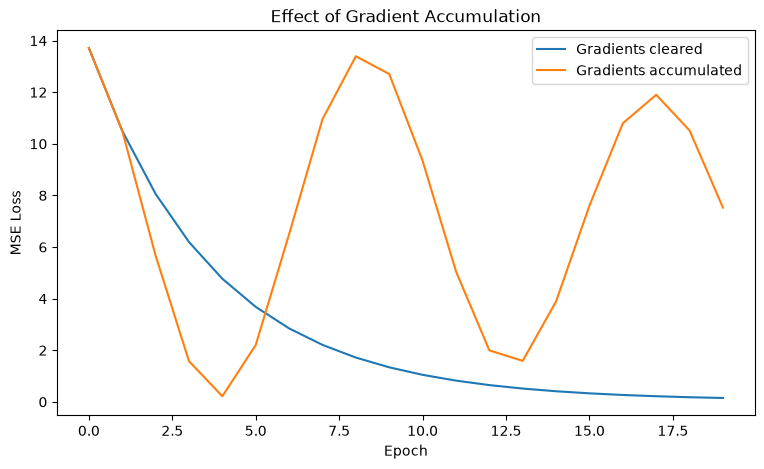

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    correct["losses"],
    label="Gradients cleared"
)

plt.plot(
    accumulated["losses"],
    label="Gradients accumulated"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Effect of Gradient Accumulation")
plt.legend()
plt.show()

## Gradient Accumulation Experiment — Interpretation

PyTorch gradients accumulate by default.

Calling:

```python
loss.backward()
```

does not automatically replace the existing values stored in:

```python
w.grad
b.grad
```

Instead, newly computed gradients are added to them.

If gradients from consecutive epochs are:

```text
g1
g2
g3
```

then normal training with gradient clearing uses:

```text
epoch 1 → g1
epoch 2 → g2
epoch 3 → g3
```

Without clearing gradients, the effective gradients become:

```text
epoch 1 → g1
epoch 2 → g1 + g2
epoch 3 → g1 + g2 + g3
```

### Results

With gradients cleared every epoch:

```text
w = 2.8542
b = 1.7673
final loss = 0.1496
```

The parameters steadily moved toward the underlying relationship:

```text
w ≈ 3
b ≈ 2
```

and the loss decreased smoothly.

Without clearing gradients:

```text
w = 2.3282
b = 0.0266
final loss = 7.5267
```

The loss initially decreased, but then began oscillating substantially.

### Why does this happen?

A gradient describes the loss surface at the **current parameter values**.

For example:

```text
parameter state #1
      ↓
compute gradient g1

parameter state #2
      ↓
compute gradient g2

parameter state #3
      ↓
compute gradient g3
```

Once the parameters have changed, an old gradient was calculated for an older
location on the loss surface.

For ordinary gradient descent, we normally want the next update to use the
gradient corresponding to the current parameter state.

Without gradient clearing:

```text
old gradients
      +
current gradient
      ↓
parameter update
```

Old gradient information keeps influencing later updates.

This can cause the optimizer to overshoot, oscillate, or otherwise behave very
differently from ordinary gradient descent.

That explains the observed loss curve:

```text
correct training
→ smooth decrease in loss

gradients not cleared
→ loss decreases
→ overshoots
→ increases
→ changes direction
→ oscillates
```

### Why do we call `zero_()`?

After every normal parameter update we use:

```python
w.grad.zero_()
b.grad.zero_()
```

This resets the gradient buffers to zero before the next backward pass.

The intended training cycle is therefore:

```text
forward pass
      ↓
compute loss
      ↓
backward()
      ↓
current gradients
      ↓
update parameters
      ↓
clear gradients
      ↓
next iteration
```

### Important nuance: gradient accumulation is sometimes intentional

Gradient accumulation itself is not inherently an error.

In larger models, GPU memory may prevent us from processing a desired large
batch at once.

For example, instead of processing a batch of 128 examples directly, we might
process:

```text
mini-batch 1 → 32 examples
mini-batch 2 → 32 examples
mini-batch 3 → 32 examples
mini-batch 4 → 32 examples
```

and intentionally accumulate the gradients across those four mini-batches.

Then:

```text
accumulate several gradients
        ↓
perform one optimizer step
        ↓
clear gradients
```

This approximates training with a larger effective batch size.

So the important distinction is:

```text
unintentional accumulation
→ bug

controlled accumulation
→ useful training technique
```

### Key takeaway

PyTorch's `.grad` field behaves like an accumulator.

Therefore, during ordinary training:

```text
backward
→ update
→ clear gradients
→ repeat
```

Forgetting the gradient reset changes the optimization algorithm itself.

## Moving from Manual Parameters to `nn.Module`

So far, the model has been represented manually using:

```python
w = torch.randn(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
```

and predictions were computed with:

```python
y_pred = x @ w + b
```

This is useful for understanding training from first principles, but real PyTorch models are usually represented using:

```python
torch.nn.Module
```

An `nn.Module` is a container for:

- learnable parameters
- layers
- the forward computation
- nested model components

For linear regression, PyTorch already provides:

```python
nn.Linear
```

Conceptually:

```text
manual model

x @ w + b

        ↓

PyTorch abstraction

nn.Linear
```

The mathematics is the same.

The abstraction simply manages the parameters for us.

In [31]:
import torch.nn as nn

# A linear layer with:
# 1 input feature
# 1 output feature
model = nn.Linear(1, 1)

print(model)

Linear(in_features=1, out_features=1, bias=True)


In [32]:
# Inspect the parameters that PyTorch created automatically
for name, parameter in model.named_parameters():
    print(
        name,
        "| shape:", parameter.shape,
        "| requires_grad:", parameter.requires_grad
    )

weight | shape: torch.Size([1, 1]) | requires_grad: True
bias | shape: torch.Size([1]) | requires_grad: True


### What `nn.Linear(1, 1)` represents

The layer:

```python
nn.Linear(1, 1)
```

implements:

$$
\hat{y} = xW^T + b
$$

For this one-dimensional example:

```text
input features  = 1
output features = 1
```

so the parameters are:

```text
weight → [1, 1]
bias   → [1]
```

These correspond directly to the manually created:

```text
w
b
```

from the previous experiment.

One small implementation detail is that `nn.Linear` stores weights in a layout
that works naturally for layers with many input and output features.

For this simple one-feature case, the distinction is not important yet.

In [33]:
# Calling the model automatically runs its forward computation
y_pred = model(x)

print("Prediction shape:", y_pred.shape)
print("First 5 predictions:")
print(y_pred[:5])

Prediction shape: torch.Size([100, 1])
First 5 predictions:
tensor([[0.6400],
        [0.6311],
        [0.6223],
        [0.6134],
        [0.6046]], grad_fn=<SliceBackward0>)


In [34]:
print("Weight:")
print(model.weight)

print("\nBias:")
print(model.bias)

Weight:
Parameter containing:
tensor([[-0.2191]], requires_grad=True)

Bias:
Parameter containing:
tensor([0.2018], requires_grad=True)


## Replace manual MSE with `nn.MSELoss`

Use the built-in loss with its default mean reduction, then compare it with the manual expression. This checks that the abstraction preserves the objective. Expect the same scalar value and a difference of zero.

In [35]:
# PyTorch's built-in Mean Squared Error loss
loss_fn = nn.MSELoss()

loss = loss_fn(y_pred, y)

print("Loss:", loss.item())

Loss: 17.38536834716797


In [36]:
loss_fn(y_pred, y)

tensor(17.3854, grad_fn=<MseLossBackward0>)

In [37]:
manual_loss = ((y_pred - y) ** 2).mean()
pytorch_loss = loss_fn(y_pred, y)

print("Manual MSE:", manual_loss.item())
print("nn.MSELoss:", pytorch_loss.item())
print(
    "Difference:",
    abs(manual_loss.item() - pytorch_loss.item())
)

Manual MSE: 17.38536834716797
nn.MSELoss: 17.38536834716797
Difference: 0.0


The saved comparison reports a difference of 0.0. `nn.MSELoss` packages the same mean squared error used in the manual experiment.

## Introducing an Optimizer

Previously, we updated parameters manually:

```python
with torch.no_grad():
    w -= learning_rate * w.grad
    b -= learning_rate * b.grad
```

PyTorch optimizers package this update logic.

For standard gradient descent, we can use:

```python
torch.optim.SGD
```

The optimizer receives the model parameters:

```python
model.parameters()
```

and applies updates using their gradients.

Conceptually:

```text
manual

w -= learning_rate * w.grad
b -= learning_rate * b.grad

        ↓

PyTorch

optimizer.step()
```

The optimizer does not compute the gradients.

`loss.backward()` still does that.

The optimizer simply uses the gradients that are already stored in the
parameters.

Expect SGD to use the existing parameter gradients when `optimizer.step()` runs; creating the optimizer alone does not change the model.

In [38]:
import torch.optim as optim

learning_rate = 0.05

optimizer = optim.SGD(
    model.parameters(),
    lr=learning_rate
)

print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.05
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


## Train with the PyTorch abstractions

Reset the seed and create a fresh `nn.Linear` model, MSE loss, and SGD optimizer. Repeat zero gradients → forward → loss → backward → step for 100 epochs. Expect the same convergence behavior as the manual loop, although the layer initialization differs.

In [39]:
# Recreate the model so training starts from fresh parameters
torch.manual_seed(42)

model = nn.Linear(1, 1)

loss_fn = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.05
)

epochs = 100
loss_history_nn = []

for epoch in range(epochs):
    # 1. Clear gradients from the previous iteration
    optimizer.zero_grad()

    # 2. Forward pass
    y_pred = model(x)

    # 3. Compute loss
    loss = loss_fn(y_pred, y)

    # Save loss for visualization
    loss_history_nn.append(loss.item())

    # 4. Backward pass
    loss.backward()

    # 5. Update all model parameters
    optimizer.step()

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"w: {model.weight.item():.4f} | "
            f"b: {model.bias.item():.4f}"
        )

Epoch   0 | Loss: 8.2153 | w: 1.0682 | b: 0.9482
Epoch  10 | Loss: 0.5725 | w: 2.5501 | b: 1.6410
Epoch  20 | Loss: 0.0787 | w: 2.8935 | b: 1.8826
Epoch  30 | Loss: 0.0421 | w: 2.9730 | b: 1.9669
Epoch  40 | Loss: 0.0389 | w: 2.9915 | b: 1.9962
Epoch  50 | Loss: 0.0386 | w: 2.9958 | b: 2.0065
Epoch  60 | Loss: 0.0385 | w: 2.9968 | b: 2.0100
Epoch  70 | Loss: 0.0385 | w: 2.9970 | b: 2.0113
Epoch  80 | Loss: 0.0385 | w: 2.9970 | b: 2.0117
Epoch  90 | Loss: 0.0385 | w: 2.9970 | b: 2.0119


In [40]:
print("Final weight:", model.weight.item())
print("Final bias:", model.bias.item())
print("Final loss:", loss_history_nn[-1])

print("\nTrue weight: 3")
print("True bias: 2")

Final weight: 2.997051477432251
Final bias: 2.0119216442108154
Final loss: 0.03851611539721489

True weight: 3
True bias: 2


The saved model again approaches $w\approx3$ and $b\approx2$. `nn.Linear`, `nn.MSELoss`, and SGD automate parameter registration, the objective, and updates while preserving the training-loop mechanics. The reported loss is recorded before the last update.

## Optimizer Comparison — SGD vs Adam vs AdamW

So far we used:

```python
torch.optim.SGD
```

An optimizer determines how model parameters are updated using the gradients
computed by:

```python
loss.backward()
```

The training loop structure stays the same:

```text
forward
→ loss
→ backward
→ optimizer step
→ repeat
```

What changes is the rule used to convert gradients into parameter updates.

### SGD

Basic stochastic gradient descent updates parameters approximately as:

$$
\theta_{t+1}
=
\theta_t
-
\eta g_t
$$

where:

- $\theta_t$ = current parameter
- $\eta$ = learning rate
- $g_t$ = current gradient

SGD uses the current gradient directly.

---

### Adam

Adam maintains running estimates of:

```text
first moment
→ roughly the running average of gradients

second moment
→ roughly the running average of squared gradients
```

This lets Adam adapt the effective step size separately for different parameters.

Conceptually:

```text
gradient
   ↓
track gradient history
   ↓
track gradient magnitude history
   ↓
adaptive parameter update
```

Adam often reaches useful solutions quickly and is widely used in deep learning.

---

### AdamW

AdamW is closely related to Adam, but handles **weight decay** separately from
the gradient-based parameter update.

This matters because weight decay is intended to regularize model parameters.

AdamW is widely used for training modern Transformer and LLM models.

For this tiny regression problem, the difference between Adam and AdamW may be
small, especially if weight decay is zero.

The purpose of this experiment is to understand the APIs and compare their
optimization behavior under controlled conditions.

Use the same initialization, 100 epochs, and learning rate 0.05. Expect distinct loss curves and parameters near the generating line. AdamW uses its default weight decay of 0.01 here, while Adam uses 0.0; this is an API comparison rather than a separately tuned optimizer benchmark.

In [41]:
def train_with_optimizer(optimizer_name, learning_rate, epochs=100):
    # Same initialization for every experiment
    torch.manual_seed(42)

    model = nn.Linear(1, 1)
    loss_fn = nn.MSELoss()

    if optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=learning_rate
        )

    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    losses = []

    for epoch in range(epochs):
        # Clear gradients from the previous iteration
        optimizer.zero_grad()

        # Forward pass
        y_pred = model(x)

        # Compute loss
        loss = loss_fn(y_pred, y)
        losses.append(loss.item())

        # Compute gradients
        loss.backward()

        # Update parameters using the chosen optimizer
        optimizer.step()

    return {
        "optimizer": optimizer_name,
        "w": model.weight.item(),
        "b": model.bias.item(),
        "final_loss": losses[-1],
        "losses": losses,
    }

In [42]:
sgd_result = train_with_optimizer(
    "SGD",
    learning_rate=0.05
)

adam_result = train_with_optimizer(
    "Adam",
    learning_rate=0.05
)

adamw_result = train_with_optimizer(
    "AdamW",
    learning_rate=0.05
)

for result in [sgd_result, adam_result, adamw_result]:
    print(
        f"{result['optimizer']:<5} | "
        f"w={result['w']:.4f} | "
        f"b={result['b']:.4f} | "
        f"loss={result['final_loss']:.6f}"
    )

SGD   | w=2.9971 | b=2.0119 | loss=0.038516
Adam  | w=3.0196 | b=2.0162 | loss=0.039296
AdamW | w=2.9906 | b=2.0092 | loss=0.038568


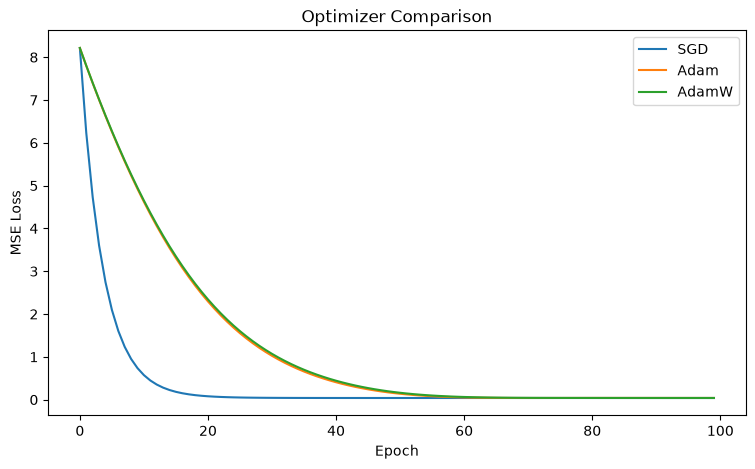

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    sgd_result["losses"],
    label="SGD"
)

plt.plot(
    adam_result["losses"],
    label="Adam"
)

plt.plot(
    adamw_result["losses"],
    label="AdamW"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## Optimizer Comparison — Interpretation

All three optimizers successfully learned parameters close to the underlying
relationship:

$$
y \approx 3x + 2
$$

The final results were:

```text
SGD
w = 2.9971
b = 2.0119
loss = 0.038516

Adam
w = 3.0196
b = 2.0162
loss = 0.039296

AdamW
w = 2.9906
b = 2.0092
loss = 0.038568
```

All three therefore reached approximately:

```text
w ≈ 3
b ≈ 2
```

However, their optimization paths were different.

### SGD

In this experiment, SGD reduced the loss much faster during the early epochs.

Basic SGD performs an update approximately as:

$$
\theta_{t+1}
=
\theta_t
-
\eta g_t
$$

where:

```text
θ = parameter
η = learning rate
g = current gradient
```

SGD therefore uses the current gradient directly.

This simple regression problem has a smooth and well-behaved loss surface, so
plain gradient descent works extremely well.

The plot shows SGD rapidly approaching the minimum.

---

### Adam

Adam uses more information than only the current gradient.

It maintains running estimates of:

```text
first moment
→ roughly the average direction of recent gradients

second moment
→ roughly the average magnitude of squared gradients
```

Very roughly:

```text
gradient history
      ↓
estimate direction
      +
estimate gradient magnitude
      ↓
adapt the update for each parameter
```

This gives Adam an adaptive learning-rate-like behavior for each parameter.

That is especially useful when:

- different parameters have gradients at very different scales
- optimization landscapes are noisy
- models contain many millions or billions of parameters
- gradients are sparse or irregular

Our current model has only two parameters:

```text
weight
bias
```

and the loss surface is extremely simple.

Adam's extra machinery therefore provides little advantage here.

With the learning rate used in this experiment, Adam actually converged more
slowly than SGD.

This does **not** imply that SGD is universally better than Adam.

It means:

> Optimizer performance depends on the problem, model, and hyperparameters.

---

## Intuition for Adam's "moments"

Suppose gradients for a parameter over several steps are:

```text
-8
-7
-9
-6
```

The gradients consistently point in the same direction.

Adam's first-moment estimate captures this history and behaves somewhat like a
smoothed gradient direction.

Instead of reacting completely independently to every individual gradient,
Adam maintains memory of recent gradients.

The second-moment estimate tracks something like:

```text
gradient²
```

so the optimizer also has information about how large gradients tend to be.

Conceptually:

```text
first moment
→ where gradients tend to point

second moment
→ how large gradients tend to be
```

Adam uses both to construct an adaptive parameter update.

---

## Why Adam and AdamW look almost identical here

In this experiment, the curves for Adam and AdamW are nearly overlapping.

That is expected.

The model contains only two parameters and the problem is extremely simple.

The default AdamW weight decay is small enough that it does not dramatically
change the solution in this case.

As models become larger, regularization and optimizer behavior become much more
important.

---

## Important lesson

This experiment should not be interpreted as:

```text
SGD > Adam > AdamW
```

There is no universal optimizer ranking.

Instead:

```text
simple smooth optimization problem
→ SGD may work extremely well

large complex neural network
→ adaptive optimizers may be easier to train

Transformer / LLM training
→ AdamW is a very common choice
```

Optimizer choice interacts with:

```text
learning rate
model architecture
gradient scale
batch size
dataset
regularization
learning-rate schedule
```

A fair optimizer comparison therefore requires tuning the learning rate and
other hyperparameters for each optimizer.

### Key takeaway

The training loop did not change:

```text
forward
→ loss
→ backward
→ optimizer.step()
```

Only the rule used by:

```python
optimizer.step()
```

changed.

That separation is one of the major benefits of the PyTorch optimizer
abstraction.

## SGD with Momentum

Plain SGD updates parameters using the current gradient:

$$
\theta_{t+1}
=
\theta_t
-
\eta g_t
$$

where:

- $\theta_t$ = current parameter
- $\eta$ = learning rate
- $g_t$ = current gradient

Momentum adds a running velocity that remembers part of the previous update direction:

$$
v_t
=
\beta v_{t-1}
+
g_t
$$

and then updates the parameter using:

$$
\theta_{t+1}
=
\theta_t
-
\eta v_t
$$

where:

- $v_t$ = current velocity
- $\beta$ = momentum coefficient

### Intuition

If gradients repeatedly point in roughly the same direction:

```text
step 1 → right
step 2 → right
step 3 → right
step 4 → right
```

plain SGD reacts to each gradient independently.

Momentum keeps some memory of the previous direction:

```text
current gradient
      +
previous velocity
      ↓
new velocity
      ↓
parameter update
```

This can:

- accelerate movement in consistent directions
- smooth noisy updates
- reduce zig-zagging
- help move through shallow regions

### Momentum is not accidental gradient accumulation

Without clearing gradients, PyTorch would do something like:

```text
g1
g1 + g2
g1 + g2 + g3
```

Momentum instead keeps a controlled, decaying history:

```text
recent gradients → stronger influence
older gradients  → gradually fade
```

So:

```text
unintentional gradient accumulation
→ bug

momentum
→ deliberate optimizer behavior
```

Compare momentum 0.0 and 0.9 for 50 epochs at learning rate 0.05. Expect stronger early movement with momentum, with possible overshoot near the minimum.

In [44]:
def train_with_sgd_momentum(momentum, learning_rate=0.05, epochs=50):
    # Same initialization for a fair comparison
    torch.manual_seed(42)

    model = nn.Linear(1, 1)
    loss_fn = nn.MSELoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    losses = []

    for epoch in range(epochs):
        # Clear gradients from previous iteration
        optimizer.zero_grad()

        # Forward pass
        y_pred = model(x)

        # Compute loss
        loss = loss_fn(y_pred, y)
        losses.append(loss.item())

        # Compute gradients
        loss.backward()

        # Update parameters
        optimizer.step()

    return {
        "momentum": momentum,
        "w": model.weight.item(),
        "b": model.bias.item(),
        "final_loss": losses[-1],
        "losses": losses,
    }

In [45]:
sgd_no_momentum = train_with_sgd_momentum(
    momentum=0.0
)

sgd_momentum = train_with_sgd_momentum(
    momentum=0.9
)

for result in [sgd_no_momentum, sgd_momentum]:
    print(
        f"momentum={result['momentum']:<3} | "
        f"w={result['w']:.4f} | "
        f"b={result['b']:.4f} | "
        f"loss={result['final_loss']:.6f}"
    )

momentum=0.0 | w=2.9956 | b=2.0059 | loss=0.038566
momentum=0.9 | w=2.8369 | b=2.0908 | loss=0.081686


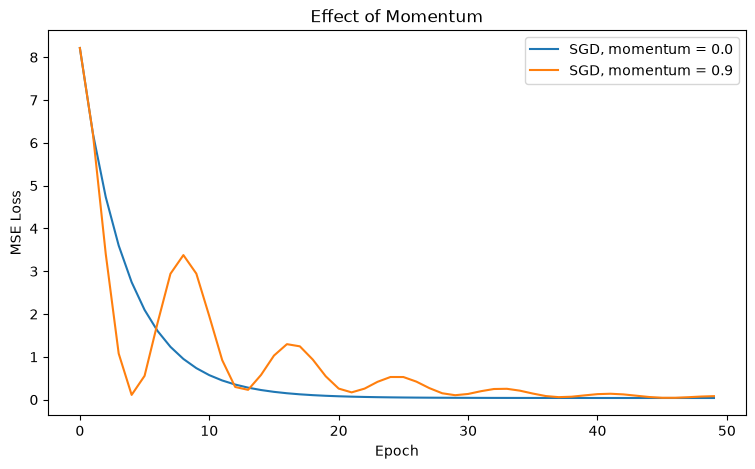

In [46]:
plt.figure(figsize=(9, 5))

plt.plot(
    sgd_no_momentum["losses"],
    label="SGD, momentum = 0.0"
)

plt.plot(
    sgd_momentum["losses"],
    label="SGD, momentum = 0.9"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Effect of Momentum")
plt.legend()
plt.show()

## Momentum Experiment — Interpretation

The comparison produced:

```text
SGD, momentum = 0.0
w = 2.9956
b = 2.0059
loss = 0.038566

SGD, momentum = 0.9
w = 2.8369
b = 2.0908
loss = 0.081686
```

The underlying parameters are approximately:

```text
w = 3
b = 2
```

### Plain SGD

Without momentum, the loss decreased smoothly toward the minimum.

```text
current gradient
      ↓
parameter update
      ↓
new gradient
      ↓
next parameter update
```

As the model approaches the minimum, the gradients become smaller, so the
updates naturally become smaller as well.

This produced stable convergence.

---

### SGD with momentum

With `momentum = 0.9`, the loss initially dropped faster.

However, the optimizer then overshot the minimum and began oscillating.

The loss curve roughly behaved like:

```text
rapid decrease
      ↓
near minimum
      ↓
overshoot
      ↓
loss increases
      ↓
direction reverses
      ↓
overshoot again
      ↓
oscillations gradually shrink
```

Momentum maintains a velocity based on previous gradients.

Using a simplified form:

$$
v_t = \beta v_{t-1} + g_t
$$

and:

$$
\theta_{t+1} = \theta_t - \eta v_t
$$

Even when the current gradient becomes small near the minimum, the accumulated
velocity may still be large.

The optimizer therefore does not immediately stop near the minimum.

It can continue moving past it.

---

## Why momentum was worse here

Momentum is not guaranteed to improve optimization.

Our experiment used:

```text
learning rate = 0.05
momentum = 0.9
```

The learning rate already worked very well for plain SGD.

Adding strong momentum made the effective updates more aggressive.

The combination therefore overshot the minimum repeatedly.

This demonstrates an important principle:

> Optimizer hyperparameters interact with each other.

For momentum SGD, both of these matter:

```text
learning rate
momentum coefficient
```

A learning rate that works well without momentum may not be optimal after
momentum is introduced.

---

## Momentum vs accidental gradient accumulation

The oscillation might look similar to the earlier experiment where gradients
were not cleared, but the mechanisms are different.

Accidental accumulation:

```text
g1
g1 + g2
g1 + g2 + g3
g1 + g2 + g3 + g4
```

Old gradients remain indefinitely unless explicitly cleared.

Momentum uses a controlled decaying history:

```text
recent gradient
→ strong influence

older gradients
→ progressively weaker influence
```

For example, with momentum coefficient $\beta = 0.9$:

```text
most recent velocity contribution
→ × 0.9 after one step
→ × 0.9² after two steps
→ × 0.9³ after three steps
→ continues fading
```

So:

```text
gradient accumulation
→ old gradients keep accumulating directly

momentum
→ old gradient information decays over time
```

---

